In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [ ]:
#Cell 1 — Clone code
#Repository chính thức có dữ liệu HQCM và hỗ trợ tác vụ Change Classification (chcl).
%cd /kaggle/working
!git clone https://github.com/codefuse-ai/codefuse-hqcm.git
%cd /kaggle/working/codefuse-hqcm
!git rev-parse HEAD

In [ ]:
#Kiểm tra GPU và cài thư viện
#Chọn GPU trong Kaggle: Settings → Accelerator → GPU. Llama 2 7B nên chạy bằng LoRA 4-bit trên GPU có khoảng 16 GB VRAM trở lên.
import torch

print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "Không có GPU")
if not torch.cuda.is_available():
    raise RuntimeError("Hãy bật GPU trong Kaggle Settings.")
print("VRAM:", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2), "GB")

%pip install -q transformers==4.46.1 datasets==3.1.0 accelerate==1.0.1 peft==0.13.2 bitsandbytes==0.44.1 python-dotenv==1.0.1 tensorboardX==2.6.2.2

In [ ]:
# Cell 2 — Đăng nhập Hugging Face
# Cần có quyền tải model meta-llama/Llama-2-7b-hf: chấp nhận điều khoản của model trên Hugging Face và tạo access token.
from huggingface_hub import login
from getpass import getpass

token = getpass("Hugging Face access token: ")
login(token=token)
del token

print("Đăng nhập Hugging Face hoàn tất.")
#Model gốc được sử dụng là Llama 2 7B, không phải model SVM đã chạy trước đó. 

In [ ]:
# Cell 3 — Sửa các điểm tương thích trong script chính thức
# Script chính thức cần một số chỉnh sửa cho Kaggle: đọc JSON local, 
# dùng FP16 thay cho BF16 trên GPU không hỗ trợ BF16, và lưu checkpoint thường xuyên để có thể resume
from pathlib import Path

script = Path("/kaggle/working/codefuse-hqcm/hqcm/sft.py")
assert script.exists(), f"Không tìm thấy {script}"

s = script.read_text()

# Dataset JSON local
old = "raw_dataset = load_dataset(arg_dataset, opt_dataset_config, split=opt_dataset_split)"
new = """raw_dataset = load_dataset(
    "json",
    data_files={opt_dataset_split: os.path.join(arg_dataset, f"{opt_dataset_split}.json")},
    split=opt_dataset_split
)"""
if old in s:
    s = s.replace(old, new)

# Tương thích GPU Kaggle dùng FP16
s = s.replace("bnb_4bit_compute_dtype=torch.bfloat16",
              "bnb_4bit_compute_dtype=torch.float16")
s = s.replace("bf16=True,", "bf16=False,\n    fp16=True,")

# Tránh tạo quá nhiều worker trong Kaggle
s = s.replace("opt_num_proc = os.cpu_count()",
              "opt_num_proc = min(os.cpu_count() or 2, 4)")

# Lưu checkpoint thường xuyên
s = s.replace("opt_output_save_steps = 1000",
              "opt_output_save_steps = 25")

script.write_text(s)
print("Đã cập nhật:", script)

In [ ]:
# Cell A — Kiểm tra quyền truy cập model gốc
from kaggle_secrets import UserSecretsClient
from huggingface_hub import HfApi

token = UserSecretsClient().get_secret("HF_TOKEN")
assert token, "Chưa cấu hình Kaggle Secret HF_TOKEN"

api = HfApi()
info = api.model_info(
    "meta-llama/Llama-2-7b-hf",
    token=token
)

print("Model:", info.id)
print("Commit:", info.sha)
print("Có thể truy cập model gốc.")


In [3]:
from kaggle_secrets import UserSecretsClient
from huggingface_hub import HfApi

token = UserSecretsClient().get_secret("kaggle-llama")

api = HfApi()
info = api.model_info(
    "meta-llama/Llama-2-7b-hf",
    token=token
)

print("Model:", info.id)
print("Commit:", info.sha)
print("Có thể truy cập model gốc.")

Model: meta-llama/Llama-2-7b-hf
Commit: 01c7f73d771dfac7d292323805ebc428287df4f9
Có thể truy cập model gốc.


In [ ]:
import os

root_dir = "/kaggle/working/codefuse-hqcm"

for root, dirs, files in os.walk(root_dir):
    level = root.replace(root_dir, "").count(os.sep)
    indent = "    " * level

    print(f"{indent}{os.path.basename(root)}/")

    sub_indent = "    " * (level + 1)
    for file in files:
        print(f"{sub_indent}{file}")

In [ ]:
!pip install unidiff

In [ ]:
%cd /kaggle/working/codefuse-hqcm

# Sửa args.fewshot thành args.few_shot
!sed -i 's/args\.fewshot/args.few_shot/g' hqcm/xdata.py

In [ ]:
#chuẩn bị dữ liệu
%cd /kaggle/working/codefuse-hqcm

!python -m hqcm.xdata \
    --task chcl \
    --output /kaggle/working/hqcm_chcl \
    ./dataset/

In [ ]:
import os

print(os.listdir("/kaggle/working/hqcm_chcl"))

In [ ]:
import json
from pathlib import Path

DATA = Path("/kaggle/working/hqcm_chcl")

for name in ["train.json", "test.json"]:
    with open(DATA / name, encoding="utf-8") as f:
        rows = json.load(f)

    print(f"\n{name}: {len(rows)} mẫu")
    print("Các trường:", list(rows[0].keys()))
    print("Mẫu đầu tiên:", rows[0])

In [ ]:
# Cell B — Fine-tune HQCM / Change Classification

from pathlib import Path
import os

ROOT = Path("/kaggle/working/codefuse-hqcm")
DATA = Path("/kaggle/working/hqcm_chcl")
OUTPUT = Path("/kaggle/working/hqcm_llama2_7b_chcl")

assert (ROOT / "hqcm" / "sft.py").exists(), "Không tìm thấy sft.py"
assert (DATA / "train.json").exists(), "Không tìm thấy hqcm_chcl/train.json"
assert (DATA / "test.json").exists(), "Không tìm thấy hqcm_chcl/test.json"

# Xác nhận dữ liệu đúng định dạng SFT
import json

with open(DATA / "train.json", encoding="utf-8") as f:
    train_rows = json.load(f)

assert len(train_rows) > 0, "Train dataset rỗng"

In [ ]:
import json
from pathlib import Path

DATA = Path("/kaggle/working/hqcm_chcl")

with open(DATA / "train.json", encoding="utf-8") as f:
    train_rows = json.load(f)

print("Số mẫu train:", len(train_rows))
print("Các trường:", list(train_rows[0].keys()))
print("Kiểm tra prompt:", "prompt" in train_rows[0])
print("Kiểm tra answer:", "answer" in train_rows[0])

In [ ]:
!pip install -U peft bitsandbytes triton

In [ ]:
!pip install -U "torchao>=0.16.0"

In [ ]:
import torch
import peft
import bitsandbytes as bnb
import triton

print("PyTorch:", torch.__version__)
print("CUDA của PyTorch:", torch.version.cuda)
print("GPU khả dụng:", torch.cuda.is_available())
print("PEFT:", peft.__version__)
print("bitsandbytes:", bnb.__version__)
print("Triton:", triton.__version__)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

In [4]:
#Đây là Cell fine-tuning hoàn chỉnh cho HQCM với Llama 2 7B, dùng dataset đã xử lý có 4.611 mẫu.

# Cell B — Fine-tune HQCM / Change Classification

from pathlib import Path
import os
import json

ROOT = Path("/kaggle/working/codefuse-hqcm")
DATA = Path("/kaggle/working/hqcm_chcl")
OUTPUT = Path("/kaggle/working/hqcm_llama2_7b_chcl")

# 1. Kiểm tra đường dẫn
assert (ROOT / "hqcm" / "sft.py").exists(), "Không tìm thấy hqcm/sft.py"
assert (DATA / "train.json").exists(), "Không tìm thấy train.json"
assert (DATA / "test.json").exists(), "Không tìm thấy test.json"

with open(DATA / "train.json", encoding="utf-8") as f:
    train_rows = json.load(f)

assert len(train_rows) > 0, "Train dataset rỗng"
assert {"prompt", "answer"}.issubset(train_rows[0].keys()), \
    f"Sai định dạng: {list(train_rows[0].keys())}"

print("Train samples:", len(train_rows))
print("Dataset:", DATA)
print("Output:", OUTPUT)

# 2. Kiểm tra Hugging Face token đã có trong biến token từ Cell A
assert "token" in globals() and token, \
    "Chưa có biến token. Hãy chạy Cell A để xác thực Hugging Face."

os.environ["HF_TOKEN"] = token
os.makedirs(OUTPUT, exist_ok=True)

# 3. Bắt đầu fine-tuning
%cd /kaggle/working/codefuse-hqcm

!python -u -m hqcm.sft \
    --seed 0 \
    --learning-rate 2e-4 \
    --num-epochs 5 \
    --batch-size 1 \
    --micro-batch-size 1 \
    --lora-rank 64 \
    --lora-alpha 16 \
    --lora-dropout 0.1 \
    --quantization -1 \
    --dataset /kaggle/working/hqcm_chcl \
    --split train \
    --max-length 512 \
    --output /kaggle/working/hqcm_llama2_7b_chcl \
    meta-llama/Llama-2-7b-hf


Train samples: 4611
Dataset: /kaggle/working/hqcm_chcl
Output: /kaggle/working/hqcm_llama2_7b_chcl
/kaggle/working/codefuse-hqcm
Failed to load /usr/local/lib/python3.13/dist-packages/torchao/_C_cutlass_90a.abi3.so: Could not load this library: /usr/local/lib/python3.13/dist-packages/torchao/_C_cutlass_90a.abi3.so
Failed to load /usr/local/lib/python3.13/dist-packages/torchao/_C_mxfp8.cpython-310-x86_64-linux-gnu.so: Could not load this library: /usr/local/lib/python3.13/dist-packages/torchao/_C_mxfp8.cpython-310-x86_64-linux-gnu.so
{'batch_size': 1,
 'config': None,
 'dataset': '/kaggle/working/hqcm_chcl',
 'learning_rate': 0.0002,
 'lora_alpha': 16,
 'lora_dropout': 0.1,
 'lora_rank': 64,
 'max_length': 512,
 'micro_batch_size': 1,
 'model': 'meta-llama/Llama-2-7b-hf',
 'no_lora': False,
 'num_epochs': 5,
 'output': '/kaggle/working/hqcm_llama2_7b_chcl',
 'percentage': 100,
 'quantization': -1,
 'resume': False,
 'seed': 0,
 'split': 'train'}
tokenizer_config.json: 100%|█████████████

In [5]:
#Zip model đã train
import os
import shutil

model_dir = "/kaggle/working/hqcm_llama2_7b_chcl"
zip_base = "/kaggle/working/hqcm_llama2_7b_chcl_backup"

assert os.path.isdir(model_dir), f"Không tìm thấy: {model_dir}"

zip_path = shutil.make_archive(
    zip_base,
    "zip",
    root_dir="/kaggle/working",
    base_dir="hqcm_llama2_7b_chcl"
)

print(f"Đã tạo: {zip_path}")
print(f"Kích thước: {os.path.getsize(zip_path) / (1024**3):.2f} GB")

Đã tạo: /kaggle/working/hqcm_llama2_7b_chcl_backup.zip
Kích thước: 1.84 GB


In [6]:
#Tìm 3 checkpoint tốt nhất để zip
import os, glob

model_dir = "/kaggle/working/hqcm_llama2_7b_chcl"

checkpoints = sorted(
    glob.glob(os.path.join(model_dir, "checkpoint-*")),
    key=lambda p: int(os.path.basename(p).split("-")[-1])
)

print("Số checkpoint:", len(checkpoints))
for p in checkpoints:
    print(os.path.basename(p),
          f"{sum(os.path.getsize(os.path.join(r, f)) for r, _, fs in os.walk(p) for f in fs) / (1024**3):.2f} GB")

Số checkpoint: 5
checkpoint-22975 0.38 GB
checkpoint-23000 0.38 GB
checkpoint-23025 0.38 GB
checkpoint-23050 0.38 GB
checkpoint-23055 0.38 GB


In [7]:
import os, shutil

assert len(checkpoints) > 0, "Không tìm thấy checkpoint nào!"

backup_dir = "/kaggle/working/selected_checkpoints"
os.makedirs(backup_dir, exist_ok=True)

for ckpt in checkpoints[-3:]:
    dest = os.path.join(backup_dir, os.path.basename(ckpt))
    if os.path.exists(dest):
        shutil.rmtree(dest)
    shutil.copytree(ckpt, dest)
    print("Đã copy:", os.path.basename(ckpt))

zip_path = shutil.make_archive(
    "/kaggle/working/hqcm_3_checkpoints",
    "zip",
    root_dir=backup_dir
)
print("ZIP:", zip_path)

Đã copy: checkpoint-23025
Đã copy: checkpoint-23050
Đã copy: checkpoint-23055
ZIP: /kaggle/working/hqcm_3_checkpoints.zip


In [12]:
!cd /kaggle/working && zip -r hqcm_chcl.zip hqcm_chcl

  adding: hqcm_chcl/ (stored 0%)
  adding: hqcm_chcl/test.json (deflated 89%)
  adding: hqcm_chcl/train.json (deflated 89%)


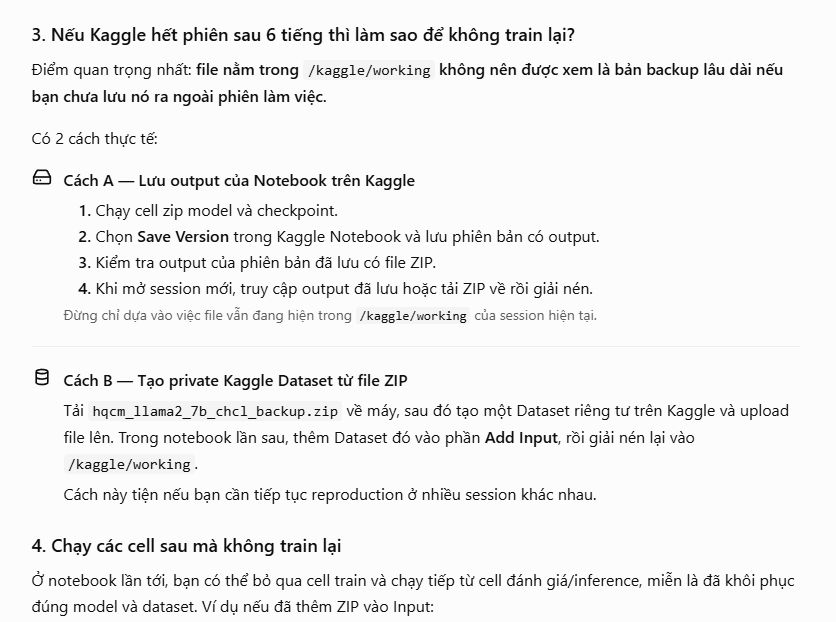

In [ ]:
import os, glob, zipfile

zip_files = glob.glob("/kaggle/input/**/hqcm_llama2_7b_chcl_backup.zip",
                      recursive=True)
assert zip_files, "Chưa tìm thấy ZIP trong Kaggle Input"

with zipfile.ZipFile(zip_files[0]) as z:
    z.extractall("/kaggle/working")

model_dir = "/kaggle/working/hqcm_llama2_7b_chcl"
print("Model directory exists:", os.path.isdir(model_dir))
print(os.listdir(model_dir)[:20])

In [8]:
# Bước 2 — Kiểm tra model đã lưu gồm những gì
# Chạy cell sau để biết thư mục model của bạn lưu LoRA adapter hay full model. Điều này quan trọng để lần sau nạp model mà không phải train lại.
import os

model_dir = "/kaggle/working/hqcm_llama2_7b_chcl"

print("Các file ở thư mục model:")
for name in sorted(os.listdir(model_dir)):
    path = os.path.join(model_dir, name)
    if os.path.isfile(path):
        print(f"{name:40s} {os.path.getsize(path) / (1024**2):8.2f} MB")
    else:
        print(f"{name}/")

Các file ở thư mục model:
README.md                                    0.00 MB
adapter_config.json                          0.00 MB
adapter_model.safetensors                  128.02 MB
checkpoint-22975/
checkpoint-23000/
checkpoint-23025/
checkpoint-23050/
checkpoint-23055/
command.txt                                  0.00 MB
events.out.tfevents.1791901732.a72d8f7730ce.351.0     0.47 MB
training_args.bin                            0.01 MB


In [ ]:
import os, glob, zipfile

zip_files = glob.glob("/kaggle/input/**/hqcm_3_checkpoints.zip",
                      recursive=True)
assert zip_files, "Chưa tìm thấy ZIP trong Kaggle Input"

with zipfile.ZipFile(zip_files[0]) as z:
    z.extractall("/kaggle/working")

model_dir = "/kaggle/working/hqcm_3_checkpoints"
print("Model directory exists:", os.path.isdir(model_dir))
print(os.listdir(model_dir)[:20])

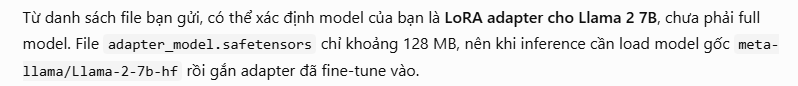

In [9]:
#Bước 1 — Kiểm tra các file backup
import os

print("Adapter:")
print(os.path.exists(
    "/kaggle/working/hqcm_llama2_7b_chcl/adapter_model.safetensors"
))

print("Training data:")
print(os.path.exists("/kaggle/working/hqcm_chcl"))

print("Model backup:")
print(os.path.exists(
    "/kaggle/working/hqcm_llama2_7b_chcl_backup.zip"
))

print("Checkpoint backup:")
print(os.path.exists(
    "/kaggle/working/hqcm_3_checkpoints.zip"
))

Adapter:
True
Training data:
True
Model backup:
True
Checkpoint backup:
True


In [10]:
#Bước 2 — Load model đã fine-tune
#Chạy cell sau để load adapter cuối cùng từ thư mục model hiện tại:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM
from peft import PeftModel

BASE_MODEL = "meta-llama/Llama-2-7b-hf"
ADAPTER_PATH = "/kaggle/working/hqcm_llama2_7b_chcl"

tokenizer = AutoTokenizer.from_pretrained(
    BASE_MODEL,
    use_fast=False
)

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

base_model = AutoModelForCausalLM.from_pretrained(
    BASE_MODEL,
    torch_dtype=torch.float16,
    device_map="auto"
)

model = PeftModel.from_pretrained(
    base_model,
    ADAPTER_PATH
)

model.eval()

print("Loaded base model and LoRA adapter successfully.")
#Lưu ý: Model gốc Llama 2 cần quyền truy cập Hugging Face được cấp phép. 
#Nếu Kaggle báo lỗi xác thực hoặc thiếu bộ nhớ GPU, hãy xử lý lỗi đó trước khi chạy đánh giá

Failed to load /usr/local/lib/python3.13/dist-packages/torchao/_C_cutlass_90a.abi3.so: Could not load this library: /usr/local/lib/python3.13/dist-packages/torchao/_C_cutlass_90a.abi3.so
Failed to load /usr/local/lib/python3.13/dist-packages/torchao/_C_mxfp8.cpython-310-x86_64-linux-gnu.so: Could not load this library: /usr/local/lib/python3.13/dist-packages/torchao/_C_mxfp8.cpython-310-x86_64-linux-gnu.so


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

Loaded base model and LoRA adapter successfully.


In [11]:
# Bước 3 — Kiểm tra một mẫu dự đoán
# Vì dataset của bạn có hai trường prompt và answer, ta có thể thử inference bằng một prompt thực tế:
from pathlib import Path
import json

DATA_DIR = Path("/kaggle/working/hqcm_chcl")

# Liệt kê file dữ liệu để xác định đúng file test
for path in DATA_DIR.rglob("*"):
    if path.is_file():
        print(path)

# Chạy cell này trước để xem chính xác định dạng và tên file test. 
# Đừng tự đoán tên file hoặc định dạng dữ liệu, vì bước tiếp theo sẽ phụ thuộc vào kết quả này.

/kaggle/working/hqcm_chcl/test.json
/kaggle/working/hqcm_chcl/train.json


In [13]:
# Kiểm tra cấu trúc dữ liệu test
# Chạy cell này trong Kaggle để xác nhận định dạng JSON và xem một mẫu dữ liệu thực tế:
import json

TEST_PATH = "/kaggle/working/hqcm_chcl/test.json"

with open(TEST_PATH, "r", encoding="utf-8") as f:
    test_data = json.load(f)

print("Kiểu dữ liệu:", type(test_data).__name__)

if isinstance(test_data, list):
    print("Số mẫu test:", len(test_data))
    print("\nCác trường của mẫu đầu tiên:")
    print(test_data[0].keys())
    print("\nPROMPT:")
    print(test_data[0]["prompt"][:2000])
    print("\nANSWER:")
    print(test_data[0]["answer"])

elif isinstance(test_data, dict):
    print("Các key cấp cao nhất:", test_data.keys())
    print(json.dumps(test_data, ensure_ascii=False, indent=2)[:4000])

Kiểu dữ liệu: list
Số mẫu test: 518

Các trường của mẫu đầu tiên:
dict_keys(['prompt', 'answer'])

PROMPT:
A git commit can typically be classified into specific categories by examining its code changes and commit message. These categories include:

- "style": Changes that solely improve the code's formatting and appearance without affecting functionality (e.g., adjusting whitespace, fixing indentation, cleaning up code formatting).
- "docs": Updates or improvements to documentation, which may include inline code comments, README files, or any other type of documentation associated with the project.
- "test": Modifications exclusively related to test code, like the addition of new tests or the correction and improvement of existing tests.
- "build": Changes that affect the build system or tools (like Gulp, Broccoli, NPM) or alterations to external dependencies (e.g., library or package updates).
- "cicd": Tweaks to configuration files or scripts used in Continuous Integration/Continuou

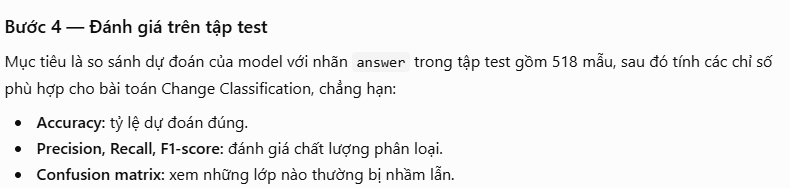

In [14]:
# Vì answer là nhãn như feat, ta có thể đánh giá trực tiếp bằng Accuracy, Precision, Recall, Macro-F1 và Weighted-F1 trên 518 mẫu test.
# Bước 4 — Chạy đánh giá model
# Chạy cell dưới đây trong Kaggle. Cell sử dụng model và tokenizer đã load ở Bước 2, sinh dự đoán từ prompt, rồi so sánh với nhãn answer.

import json
import re
import torch
import pandas as pd
from tqdm.auto import tqdm
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)
from sklearn.preprocessing import LabelEncoder

TEST_PATH = "/kaggle/working/hqcm_chcl/test.json"
OUTPUT_DIR = "/kaggle/working/hqcm_llama2_7b_chcl"

with open(TEST_PATH, "r", encoding="utf-8") as f:
    test_data = json.load(f)

# Các nhãn hợp lệ trong bài toán Change Classification
LABELS = [
    "style", "docs", "test", "build",
    "cicd", "fix", "feat", "refactor"
]

def extract_label(text):
    """Trích nhãn từ đầu câu trả lời, ví dụ 'feat' hoặc 'feat ...'."""
    text = str(text).strip().lower()
    match = re.match(r"^[\s\"'`*]*(style|docs|test|build|cicd|fix|feat|refactor)\b", text)
    return match.group(1) if match else None

def predict_label(prompt):
    inputs = tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True,
        max_length=512
    )
    inputs = {k: v.to(model.device) for k, v in inputs.items()}

    with torch.inference_mode():
        output = model.generate(
            **inputs,
            max_new_tokens=16,
            do_sample=False,
            num_beams=1,
            pad_token_id=tokenizer.eos_token_id,
            eos_token_id=tokenizer.eos_token_id
        )

    # Chỉ decode phần model mới sinh, không decode lại prompt
    new_tokens = output[0][inputs["input_ids"].shape[1]:]
    generated_text = tokenizer.decode(
        new_tokens, skip_special_tokens=True
    ).strip()

    return generated_text

y_true = []
y_pred = []
raw_predictions = []
invalid_predictions = []

for i, item in enumerate(tqdm(test_data, desc="Evaluating")):
    true_label = extract_label(item["answer"])
    generated_text = predict_label(item["prompt"])
    pred_label = extract_label(generated_text)

    y_true.append(true_label)
    y_pred.append(pred_label)
    raw_predictions.append(generated_text)

    if true_label is None or pred_label is None:
        invalid_predictions.append({
            "index": i,
            "true_answer": item["answer"],
            "generated_text": generated_text,
            "parsed_true": true_label,
            "parsed_pred": pred_label
        })

# Chỉ số chính trên các mẫu có nhãn hợp lệ ở ground truth.
valid_indices = [
    i for i, label in enumerate(y_true)
    if label is not None
]

valid_true = [y_true[i] for i in valid_indices]
valid_pred = [y_pred[i] for i in valid_indices]

# Nhãn dự đoán không hợp lệ được xem là dự đoán sai,
# không loại khỏi mẫu đánh giá.
valid_pred_for_accuracy = [
    y_pred[i] if y_pred[i] is not None else "__invalid__"
    for i in valid_indices
]

accuracy = accuracy_score(
    valid_true, valid_pred_for_accuracy
)

precision, recall, f1, _ = precision_recall_fscore_support(
    valid_true,
    valid_pred_for_accuracy,
    labels=LABELS,
    average="macro",
    zero_division=0
)

weighted_precision, weighted_recall, weighted_f1, _ = (
    precision_recall_fscore_support(
        valid_true,
        valid_pred_for_accuracy,
        labels=LABELS,
        average="weighted",
        zero_division=0
    )
)

print("\n===== TEST RESULTS =====")
print(f"Total test samples: {len(test_data)}")
print(f"Valid ground-truth labels: {len(valid_indices)}")
print(f"Invalid/missing predictions: {sum(
    p is None for p in y_pred
)}")
print(f"Accuracy:          {accuracy:.4f}")
print(f"Macro Precision:   {precision:.4f}")
print(f"Macro Recall:      {recall:.4f}")
print(f"Macro F1-score:    {f1:.4f}")
print(f"Weighted F1-score: {weighted_f1:.4f}")

print("\n===== CLASSIFICATION REPORT =====")
print(classification_report(
    valid_true,
    valid_pred_for_accuracy,
    labels=LABELS,
    zero_division=0,
    digits=4
))

# Lưu kết quả dự đoán
results_df = pd.DataFrame({
    "prompt": [item["prompt"] for item in test_data],
    "true_answer": [item["answer"] for item in test_data],
    "true_label": y_true,
    "generated_text": raw_predictions,
    "predicted_label": y_pred,
    "correct": [
        (y_true[i] == y_pred[i]) if y_true[i] is not None else False
        for i in range(len(test_data))
    ]
})

csv_path = f"{OUTPUT_DIR}/test_predictions.csv"
json_path = f"{OUTPUT_DIR}/test_predictions.json"

results_df.to_csv(csv_path, index=False)
results_df.to_json(
    json_path,
    orient="records",
    force_ascii=False,
    indent=2
)

with open(f"{OUTPUT_DIR}/invalid_predictions.json", "w", encoding="utf-8") as f:
    json.dump(invalid_predictions, f, ensure_ascii=False, indent=2)

print("\nSaved predictions:")
print(csv_path)
print(json_path)

if invalid_predictions:
    print("\nVí dụ dự đoán không trích xuất được nhãn:")
    print(json.dumps(
        invalid_predictions[:5],
        ensure_ascii=False,
        indent=2
    ))

Evaluating:   0%|          | 0/518 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:590: UserWarning: `do_sample` is set to `False`. However, `temperature` is set to `0.6` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `temperature`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:595: UserWarning: `do_sample` is set to `False`. However, `top_p` is set to `0.9` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_p`.
  warnings.warn(



===== TEST RESULTS =====
Total test samples: 518
Valid ground-truth labels: 518
Invalid/missing predictions: 516
Accuracy:          0.0019
Macro Precision:   0.0625
Macro Recall:      0.0025
Macro F1-score:    0.0048
Weighted F1-score: 0.0037

===== CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

       style     0.0000    0.0000    0.0000        11
        docs     0.0000    0.0000    0.0000        40
        test     0.5000    0.0200    0.0385        50
       build     0.0000    0.0000    0.0000        11
        cicd     0.0000    0.0000    0.0000        11
         fix     0.0000    0.0000    0.0000       133
        feat     0.0000    0.0000    0.0000       114
    refactor     0.0000    0.0000    0.0000       148

   micro avg     0.5000    0.0019    0.0038       518
   macro avg     0.0625    0.0025    0.0048       518
weighted avg     0.0483    0.0019    0.0037       518


Saved predictions:
/kaggle/working/hqcm_llama2_7b_chcl/test_predictio

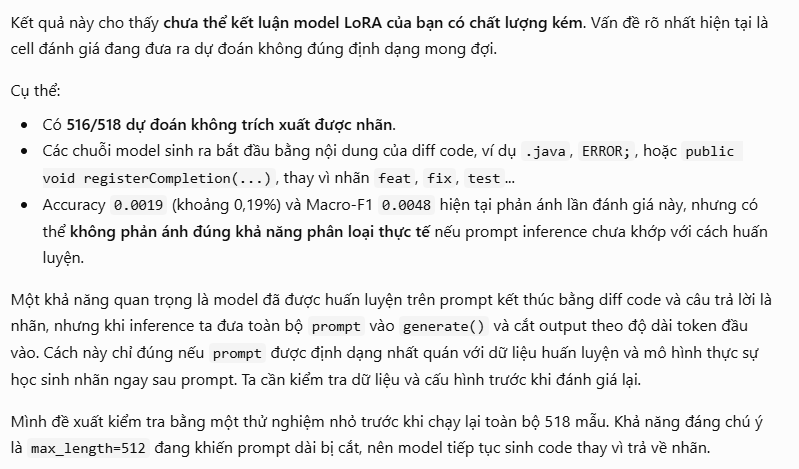

In [15]:
# Bước 5 — Kiểm tra lại cách sinh nhãn
# Chạy cell dưới đây. Cell sẽ giữ lại phần cuối của prompt khi token hóa và chỉ thử 5 mẫu, không cần train lại.
import json
import torch

TEST_PATH = "/kaggle/working/hqcm_chcl/test.json"

with open(TEST_PATH, "r", encoding="utf-8") as f:
    test_data = json.load(f)

# Chỉ dùng cho kiểm tra chẩn đoán
old_truncation_side = tokenizer.truncation_side
tokenizer.truncation_side = "left"

for i in range(5):
    item = test_data[i]

    inputs = tokenizer(
        item["prompt"],
        return_tensors="pt",
        truncation=True,
        max_length=512
    )
    inputs = {k: v.to(model.device) for k, v in inputs.items()}

    with torch.inference_mode():
        output = model.generate(
            **inputs,
            max_new_tokens=8,
            do_sample=False,
            num_beams=1,
            pad_token_id=tokenizer.eos_token_id,
            eos_token_id=tokenizer.eos_token_id,
            temperature=None,
            top_p=None
        )

    new_tokens = output[0, inputs["input_ids"].shape[1]:]
    generated = tokenizer.decode(
        new_tokens, skip_special_tokens=True
    ).strip()

    print(f"\nMẫu {i}")
    print("Nhãn thật:", item["answer"])
    print("Cuối prompt:", item["prompt"][-250:])
    print("Model sinh:", repr(generated))

tokenizer.truncation_side = old_truncation_side


Mẫu 0
Nhãn thật: feat
Cuối prompt: ified as those that have a non-empty group

```

Accompanying this code diff is its commit message:

```
Avoid creating unnecessary new instances of LaunchableGradleTaskSelector
```

Given this information, the git commit can be categorized as type: 
Model sinh: '* Performance - 10'

Mẫu 1
Nhãn thật: feat
Cuối prompt: 	priority = Log.WARN;
 		else
 			priority = Log.ERROR;
 

```

Accompanying this code diff is its commit message:

```
If NoClassDefFoundError occurs, set the log level to WARN
```

Given this information, the git commit can be categorized as type: 
Model sinh: '```\nSECURITY_'

Mẫu 2
Nhãn thật: fix
Cuối prompt: {
       if (myContext.lparenthOffset >= 0){

```

Accompanying this code diff is its commit message:

```
Add intelligent input completion termination for new after constructor
```

Given this information, the git commit can be categorized as type: 
Model sinh: '* CONSTRUCTOR'

Mẫu 3
Nhãn thật: test
Cuối prompt: + expected, 1 

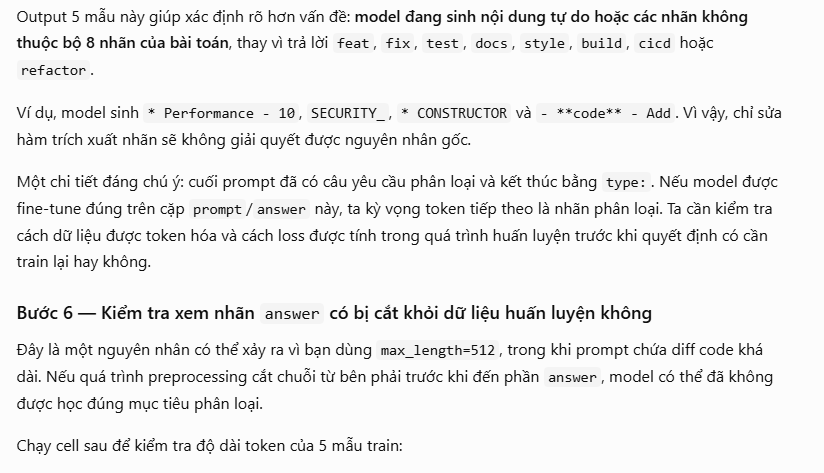

In [16]:
import json

TRAIN_PATH = "/kaggle/working/hqcm_chcl/train.json"

with open(TRAIN_PATH, "r", encoding="utf-8") as f:
    train_data = json.load(f)

print("Tổng số mẫu train:", len(train_data))
print("Tokenizer truncation_side:", tokenizer.truncation_side)

for i, item in enumerate(train_data[:5]):
    prompt = item["prompt"]
    answer = item["answer"]

    prompt_tokens = tokenizer(
        prompt, add_special_tokens=True
    )["input_ids"]

    full_tokens = tokenizer(
        prompt + answer, add_special_tokens=True
    )["input_ids"]

    truncated_tokens = tokenizer(
        prompt + answer,
        add_special_tokens=True,
        truncation=True,
        max_length=512
    )["input_ids"]

    answer_tokens = tokenizer(
        answer, add_special_tokens=False
    )["input_ids"]

    print(f"\nMẫu {i}")
    print("Nhãn:", answer)
    print("Số token prompt:", len(prompt_tokens))
    print("Số token prompt + answer:", len(full_tokens))
    print("Số token sau truncation:", len(truncated_tokens))
    print("Số token answer:", len(answer_tokens))
    print("Prompt đã dài >= 512 token:", len(prompt_tokens) >= 512)

Tổng số mẫu train: 4611
Tokenizer truncation_side: right

Mẫu 0
Nhãn: fix
Số token prompt: 676
Số token prompt + answer: 676
Số token sau truncation: 512
Số token answer: 1
Prompt đã dài >= 512 token: True

Mẫu 1
Nhãn: fix
Số token prompt: 660
Số token prompt + answer: 660
Số token sau truncation: 512
Số token answer: 1
Prompt đã dài >= 512 token: True

Mẫu 2
Nhãn: refactor
Số token prompt: 783
Số token prompt + answer: 783
Số token sau truncation: 512
Số token answer: 1
Prompt đã dài >= 512 token: True

Mẫu 3
Nhãn: fix
Số token prompt: 674
Số token prompt + answer: 674
Số token sau truncation: 512
Số token answer: 1
Prompt đã dài >= 512 token: True

Mẫu 4
Nhãn: fix
Số token prompt: 776
Số token prompt + answer: 776
Số token sau truncation: 512
Số token answer: 1
Prompt đã dài >= 512 token: True


In [17]:
#Chạy ô kiểm tra sau để xác nhận nhãn có còn trong chuỗi token bị cắt hay không:
import json

TRAIN_PATH = "/kaggle/working/hqcm_chcl/train.json"

with open(TRAIN_PATH, "r", encoding="utf-8") as f:
    train_data = json.load(f)

for i in range(5):
    prompt = train_data[i]["prompt"]
    answer = train_data[i]["answer"]

    # Kiểm tra prompt riêng và chuỗi có thêm nhãn
    prompt_ids = tokenizer(
        prompt,
        add_special_tokens=False
    )["input_ids"]

    full_text = prompt + answer
    full_ids = tokenizer(
        full_text,
        add_special_tokens=False
    )["input_ids"]

    cut_ids = tokenizer(
        full_text,
        add_special_tokens=False,
        truncation=True,
        max_length=512
    )["input_ids"]

    answer_ids = tokenizer(
        answer,
        add_special_tokens=False
    )["input_ids"]

    print(f"\nMẫu {i} | Nhãn: {answer}")
    print("Prompt token:", len(prompt_ids))
    print("Full token:", len(full_ids))
    print("Token nhãn:", answer_ids)
    print("Nhãn có trong 512 token đầu:",
          len(answer_ids) > 0 and
          cut_ids[-len(answer_ids):] == answer_ids)
    print("Đuôi chuỗi sau truncation:",
          repr(tokenizer.decode(cut_ids[-40:])))


Mẫu 0 | Nhãn: fix
Prompt token: 675
Full token: 675
Token nhãn: [2329]
Nhãn có trong 512 token đầu: False
Đuôi chuỗi sau truncation: ',12 @@ public class SLRUMap<K,V> {\n   public void put(K key, V value) {\n     V oldValue = myProtectedQueue'

Mẫu 1 | Nhãn: fix
Prompt token: 659
Full token: 659
Token nhãn: [2329]
Nhãn có trong 512 token đầu: False
Đuôi chuỗi sau truncation: 'b/hazelcast-wm/src/main/java/com/hazelcast/web/WebFilter.java\n@@ -248,8 +24'

Mẫu 2 | Nhãn: refactor
Prompt token: 782
Full token: 782
Token nhãn: [28559]
Nhãn có trong 512 token đầu: False
Đuôi chuỗi sau truncation: '-665,15 +665,8 @@ public class PsiBuilderImpl extends UserDataHolderBase implements PsiBuilder, AS\n   }\n \n   @'

Mẫu 3 | Nhãn: fix
Prompt token: 673
Full token: 673
Token nhãn: [2329]
Nhãn có trong 512 token đầu: False
Đuôi chuỗi sau truncation: 'Composer.java\n@@ -83,7 +83,7 @@ public class DescriptorComposer extends HTMLComposerImpl {\n     if (refElement instanceof'

Mẫu 4 | Nhãn: fix
Prompt 

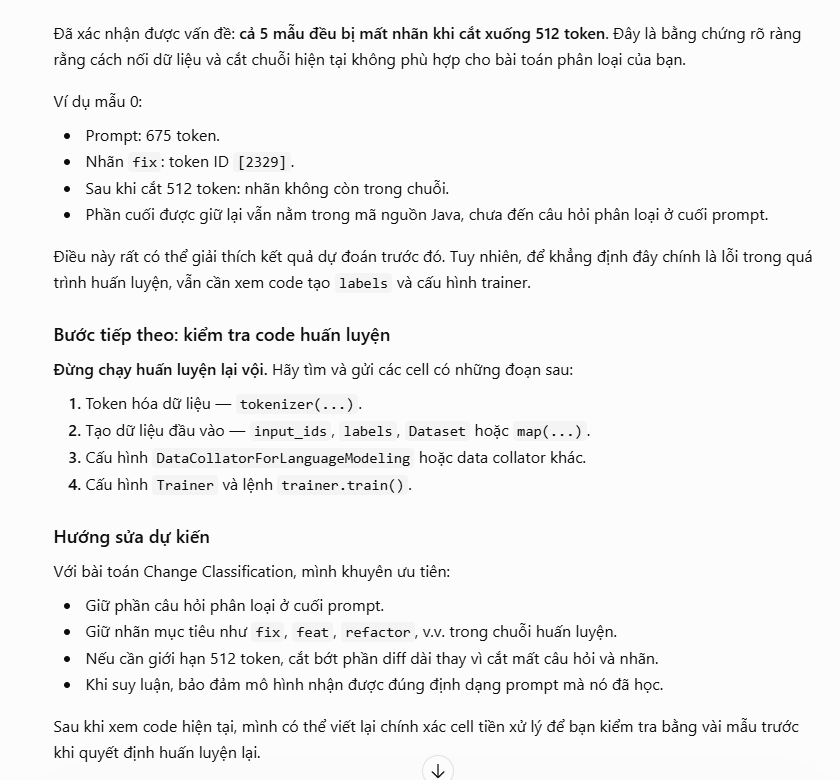

**TUNING**

In [ ]:
#Cell 2 — Cài thư viện cho baseline
!pip -q install pandas numpy scikit-learn matplotlib seaborn

In [ ]:
#Cell 3 — Kiểm tra dataset
from pathlib import Path

ROOT = Path("/kaggle/working/codefuse-hqcm")
DATA = ROOT / "dataset"

print("Dataset exists:", DATA.exists())

for p in sorted(DATA.rglob("*")):
    if p.is_file():
        print(p.relative_to(ROOT), f"({p.stat().st_size / 1024:.1f} KB)")

In [ ]:
!pip install -q unidiff

In [ ]:
# Lỗi do code hqcm/xdata.py dùng args.fewshot, nhưng tham số thực tế là args.few_shot.
# Chạy cell này để sửa lỗi trong repository:
from pathlib import Path

p = Path("/kaggle/working/codefuse-hqcm/hqcm/xdata.py")
s = p.read_text()

s = s.replace("args.fewshot", "args.few_shot")
p.write_text(s)

print("Đã sửa:", "args.few_shot" in p.read_text())

In [ ]:
#Cell 4 — Chuẩn bị dữ liệu theo pipeline chính thức
%cd /kaggle/working/codefuse-hqcm

!python -m hqcm.xdata \
    --task chcl \
    --output /kaggle/working/hqcm_chcl \
    ./dataset/

In [ ]:
#Cell 5 — Kiểm tra định dạng đầu ra
from pathlib import Path

OUT = Path("/kaggle/working/hqcm_chcl")

for p in sorted(OUT.rglob("*")):
    if p.is_file():
        print(p.relative_to(OUT), f"{p.stat().st_size / 1024:.1f} KB")

In [ ]:
# Cell 6 — Đọc mẫu dữ liệu
# Chạy cell này để xác định chính xác định dạng và tên trường của dữ liệu sau khi chuyển đổi:
import json
from pathlib import Path

for p in sorted(OUT.rglob("*")):
    if not p.is_file():
        continue

    print(f"\n--- {p.relative_to(OUT)} ---")

    try:
        if p.suffix.lower() == ".json":
            obj = json.loads(p.read_text())
            if isinstance(obj, list):
                print("Rows:", len(obj))
                print("Sample:", obj[0] if obj else None)
            else:
                print(str(obj)[:2000])

        elif p.suffix.lower() in [".jsonl", ".txt"]:
            with p.open(errors="ignore") as f:
                for _ in range(2):
                    line = f.readline()
                    if not line:
                        break
                    print(line[:1000])

        elif p.suffix.lower() == ".csv":
            import pandas as pd
            df = pd.read_csv(p)
            print("Shape:", df.shape)
            print("Columns:", df.columns.tolist())
            display(df.head(2))

    except Exception as e:
        print("Inspection error:", e)

In [ ]:
# Cell 7 — Baseline TF-IDF + Logistic Regression
# Mục đích: dùng TF-IDF biến prompt (code diff + commit message) thành vector số, sau đó Logistic Regression dự đoán nhãn commit (answer).
# Đây là baseline nhẹ để so sánh với mô hình trong paper; đánh giá Accuracy, Macro-F1 và từng lớp trên tập test 518 mẫu.
import json
import pandas as pd
import numpy as np

from pathlib import Path
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report,
    confusion_matrix
)
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

OUT = Path("/kaggle/working/hqcm_chcl")

with open(OUT / "train.json", encoding="utf-8") as f:
    train_data = json.load(f)

with open(OUT / "test.json", encoding="utf-8") as f:
    test_data = json.load(f)

train_df = pd.DataFrame(train_data)
test_df = pd.DataFrame(test_data)

# Kiểm tra dữ liệu
assert {"prompt", "answer"}.issubset(train_df.columns)
assert {"prompt", "answer"}.issubset(test_df.columns)

train_df = train_df.dropna(subset=["prompt", "answer"])
test_df = test_df.dropna(subset=["prompt", "answer"])

X_train_text = train_df["prompt"].astype(str)
y_train = train_df["answer"].astype(str)
X_test_text = test_df["prompt"].astype(str)
y_test = test_df["answer"].astype(str)

print("Train:", len(train_df), "| Test:", len(test_df))
print("\nTrain label distribution:")
print(y_train.value_counts())

# TF-IDF: chỉ fit trên train để tránh data leakage
tfidf = TfidfVectorizer(
    max_features=100_000,
    ngram_range=(1, 2),
    sublinear_tf=True,
    min_df=2,
    dtype=np.float32
)

X_train = tfidf.fit_transform(X_train_text)
X_test = tfidf.transform(X_test_text)

# Huấn luyện baseline
model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)
model.fit(X_train, y_train)

# Đánh giá
y_pred = model.predict(X_test)

print("\n=== TF-IDF + Logistic Regression ===")
print(f"Accuracy : {accuracy_score(y_test, y_pred):.4f}")
print(f"Macro-F1 : {f1_score(y_test, y_pred, average='macro', zero_division=0):.4f}")
print(f"Weighted-F1: {f1_score(y_test, y_pred, average='weighted', zero_division=0):.4f}")
print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))

# Confusion matrix
labels = sorted(set(y_test) | set(y_pred))
cm = confusion_matrix(y_test, y_pred, labels=labels)

plt.figure(figsize=(10, 7))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=labels, yticklabels=labels
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("HQCM — TF-IDF + Logistic Regression")
plt.tight_layout()
plt.show()

# Lưu model và kết quả để dùng ở session sau
RESULTS = Path("/kaggle/working/hqcm_baseline")
RESULTS.mkdir(exist_ok=True)

joblib.dump(tfidf, RESULTS / "tfidf.joblib")
joblib.dump(model, RESULTS / "logistic_regression.joblib")

pd.DataFrame({
    "actual": y_test.to_numpy(),
    "predicted": y_pred
}).to_csv(RESULTS / "predictions.csv", index=False)

metrics = {
    "accuracy": float(accuracy_score(y_test, y_pred)),
    "macro_f1": float(f1_score(y_test, y_pred, average="macro", zero_division=0)),
    "weighted_f1": float(f1_score(y_test, y_pred, average="weighted", zero_division=0)),
    "train_samples": len(train_df),
    "test_samples": len(test_df)
}
with open(RESULTS / "metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

print("\nĐã lưu model và kết quả tại:", RESULTS)

Lưu ý: class_weight="balanced" là lựa chọn cải tiến ban đầu, không phải cấu hình được xác nhận là cấu hình gốc của paper. Giữ nguyên tập test chính thức khi so sánh với baseline SVM hoặc mô hình khác.

In [ ]:
#Cell 8 — TF-IDF + Linear SVM, để so sánh với Logistic Regression trên cùng tập train/test.
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score, classification_report
import joblib
import json
from pathlib import Path

# Tái sử dụng X_train, X_test đã tạo ở Cell 7
svm = LinearSVC(
    class_weight="balanced",
    random_state=42,
    max_iter=3000
)

svm.fit(X_train, y_train)
svm_pred = svm.predict(X_test)

print("=== TF-IDF + Linear SVM ===")
print(f"Accuracy: {accuracy_score(y_test, svm_pred):.4f}")
print(f"Macro-F1: {f1_score(y_test, svm_pred, average='macro', zero_division=0):.4f}")
print(f"Weighted-F1: {f1_score(y_test, svm_pred, average='weighted', zero_division=0):.4f}")
print(classification_report(y_test, svm_pred, zero_division=0))

# Lưu mô hình và dự đoán
OUT = Path("/kaggle/working/hqcm_baseline")
joblib.dump(svm, OUT / "linear_svm.joblib")

import pandas as pd
pd.DataFrame({
    "actual": y_test.to_numpy(),
    "predicted": svm_pred
}).to_csv(OUT / "svm_predictions.csv", index=False)

with open(OUT / "svm_metrics.json", "w") as f:
    json.dump({
        "accuracy": float(accuracy_score(y_test, svm_pred)),
        "macro_f1": float(f1_score(y_test, svm_pred, average="macro", zero_division=0)),
        "weighted_f1": float(f1_score(y_test, svm_pred, average="weighted", zero_division=0))
    }, f, indent=2)

print("Đã lưu kết quả tại:", OUT)
# Mục đích: xác định mô hình cổ điển nào tốt hơn trước khi thử cải tiến. 
# Lưu ý Macro-F1 cao hơn Accuracy không có nghĩa mô hình đạt 68% accuracy; hai metric đo hai khía cạnh khác nhau.

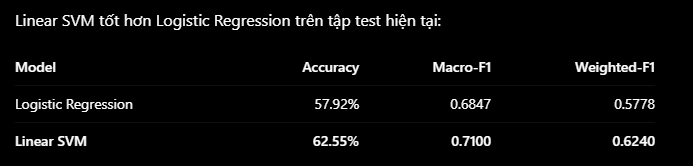

In [ ]:
# Cell 9 — cải tiến TF-IDF + Linear SVM bằng n-gram và tinh chỉnh tham số. (Tune TF-IDF + Linear SVM trên validation)
# Cell này dùng validation tách từ tập train, giữ nguyên test 518 mẫu để đánh giá cuối cùng, tránh data leakage.
import numpy as np
import pandas as pd
import json
from pathlib import Path

from sklearn.model_selection import train_test_split, ParameterGrid
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import f1_score, accuracy_score

# Chia validation chỉ từ training set
X_tr_text, X_val_text, y_tr, y_val = train_test_split(
    X_train_text,
    y_train,
    test_size=0.15,
    random_state=42,
    stratify=y_train
)

configs = [
    {"ngram_range": (1, 1), "min_df": 2, "C": 0.5},
    {"ngram_range": (1, 2), "min_df": 2, "C": 0.5},
    {"ngram_range": (1, 2), "min_df": 2, "C": 1.0},
    {"ngram_range": (1, 2), "min_df": 1, "C": 1.0},
    {"ngram_range": (1, 3), "min_df": 2, "C": 1.0},
]

results = []
best_score = -1
best_config = None

for cfg in configs:
    vec = TfidfVectorizer(
        max_features=100_000,
        ngram_range=cfg["ngram_range"],
        min_df=cfg["min_df"],
        sublinear_tf=True,
        dtype=np.float32
    )
    A = vec.fit_transform(X_tr_text)
    B = vec.transform(X_val_text)

    clf = LinearSVC(
        C=cfg["C"],
        class_weight="balanced",
        random_state=42,
        max_iter=3000
    )
    clf.fit(A, y_tr)
    pred = clf.predict(B)

    macro = f1_score(y_val, pred, average="macro", zero_division=0)
    acc = accuracy_score(y_val, pred)

    results.append({**cfg, "val_accuracy": acc, "val_macro_f1": macro})
    print(cfg, f"Accuracy={acc:.4f}, Macro-F1={macro:.4f}")

    if macro > best_score:
        best_score = macro
        best_config = cfg

print("\nBest config:", best_config)
print("Best validation Macro-F1:", round(best_score, 4))

OUT = Path("/kaggle/working/hqcm_baseline")
pd.DataFrame(results).to_csv(OUT / "tuning_results.csv", index=False)
with open(OUT / "best_config.json", "w") as f:
    json.dump(best_config, f, indent=2)
#Mục đích: tìm cấu hình tốt hơn dựa trên validation Macro-F1, đặc biệt hữu ích khi các lớp như build, cicd, style có rất ít mẫu. 

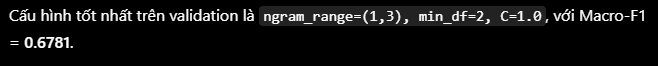

In [ ]:
# Cell 10 — Đánh giá cấu hình tốt nhất trên test (Final evaluation)
# Mục đích: huấn luyện lại trên toàn bộ tập train, đánh giá trên test 518 mẫu chưa dùng để tuning, rồi so sánh với Linear SVM baseline.
import json
import numpy as np
import pandas as pd
from pathlib import Path

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report
)

OUT = Path("/kaggle/working/hqcm_baseline")

# Cấu hình tốt nhất từ validation
tfidf_best = TfidfVectorizer(
    max_features=100_000,
    ngram_range=(1, 3),
    min_df=2,
    sublinear_tf=True,
    dtype=np.float32
)

X_train_best = tfidf_best.fit_transform(X_train_text)
X_test_best = tfidf_best.transform(X_test_text)

svm_best = LinearSVC(
    C=1.0,
    class_weight="balanced",
    random_state=42,
    max_iter=3000
)

svm_best.fit(X_train_best, y_train)
pred_best = svm_best.predict(X_test_best)

metrics_best = {
    "accuracy": float(accuracy_score(y_test, pred_best)),
    "macro_f1": float(f1_score(y_test, pred_best, average="macro", zero_division=0)),
    "weighted_f1": float(f1_score(y_test, pred_best, average="weighted", zero_division=0))
}

print("=== Tuned TF-IDF + Linear SVM ===")
for k, v in metrics_best.items():
    print(f"{k}: {v:.4f}")

print("\nClassification report:")
print(classification_report(y_test, pred_best, zero_division=0))

# Lưu mô hình và kết quả
import joblib

joblib.dump(tfidf_best, OUT / "tfidf_svm_tuned_vectorizer.joblib")
joblib.dump(svm_best, OUT / "svm_tuned.joblib")

pd.DataFrame({
    "actual": y_test.to_numpy(),
    "predicted": pred_best
}).to_csv(OUT / "tuned_predictions.csv", index=False)

with open(OUT / "tuned_metrics.json", "w") as f:
    json.dump(metrics_best, f, indent=2)

print("\nĐã lưu kết quả tại:", OUT)

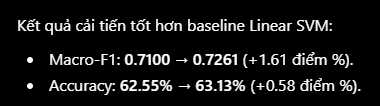

In [ ]:
# Cell 11 — So sánh và lưu bảng kết quả (Compare models)
# Mục đích: tổng hợp kết quả 3 mô hình để báo cáo reproduction và cải tiến.
import pandas as pd
import json
from pathlib import Path

OUT = Path("/kaggle/working/hqcm_baseline")

with open(OUT / "metrics.json") as f:
    lr = json.load(f)

with open(OUT / "svm_metrics.json") as f:
    svm = json.load(f)

with open(OUT / "tuned_metrics.json") as f:
    tuned = json.load(f)

comparison = pd.DataFrame([
    {
        "Model": "TF-IDF + Logistic Regression",
        "Accuracy": lr["accuracy"],
        "Macro-F1": lr["macro_f1"],
        "Weighted-F1": lr["weighted_f1"]
    },
    {
        "Model": "TF-IDF + Linear SVM",
        "Accuracy": svm["accuracy"],
        "Macro-F1": svm["macro_f1"],
        "Weighted-F1": svm["weighted_f1"]
    },
    {
        "Model": "Tuned TF-IDF + Linear SVM",
        "Accuracy": tuned["accuracy"],
        "Macro-F1": tuned["macro_f1"],
        "Weighted-F1": tuned["weighted_f1"]
    }
])

display(comparison.round(4))
comparison.to_csv(OUT / "model_comparison.csv", index=False)

print("Đã lưu:", OUT / "model_comparison.csv")

 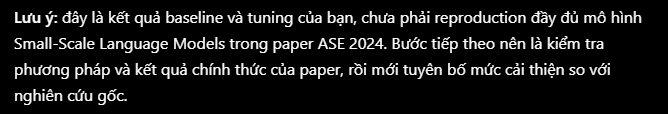

In [ ]:
#Cell 12 — Nén kết quả để backup
from pathlib import Path
import zipfile
import os

SRC = Path("/kaggle/working/hqcm_baseline")
BACKUP = Path("/kaggle/working/hqcm_baseline_backup.zip")

assert SRC.exists(), f"Không tìm thấy thư mục: {SRC}"

with zipfile.ZipFile(
    BACKUP, "w", compression=zipfile.ZIP_DEFLATED
) as z:
    for p in SRC.rglob("*"):
        if p.is_file():
            z.write(p, p.relative_to(SRC.parent))

print(f"Backup: {BACKUP}")
print(f"Size: {BACKUP.stat().st_size / 1024 / 1024:.2f} MB")

# Kiểm tra file ZIP
with zipfile.ZipFile(BACKUP, "r") as z:
    bad = z.testzip()
    print("ZIP integrity:", "OK" if bad is None else f"ERROR: {bad}")
    print("Files:", len(z.namelist()))